# スルーレート

オペアンプの出力は、どんなに速く変えようとしても、ある速さ以上では変われません。この上限を**スルーレート**(SR、単位は V/µs)といいます。大きくて速い信号では、方形波の縁が斜めになり、正弦波が三角波のようにゆがみます。オペアンプを選ぶときに、周波数特性とならんで必ず見る値です。

この回では、方形波の縁の傾き、正弦波のゆがみ、そして「振幅によって通せる周波数が変わる」ことを見ます。

## 回路

![スルーレート](04_slew_rate/circuit.svg)

ボルテージフォロワ(0-1)です。回路は同じでも、オペアンプの中では、限られた電流 $I$ で発振を防ぐためのコンデンサ $C_c$(位相補償容量)を充電して出力を動かしています。コンデンサの電圧は電流 ÷ 容量の速さでしか変われないので、出力の変化の速さは $\mathrm{SR} = I / C_c$ で頭打ちになります。

## 原理

出力の傾きの大きさが、SR を超えられません。

$$\left|\frac{dV_\mathrm{out}}{dt}\right| \le \mathrm{SR}$$

| 入力 | 出力 |
|---|---|
| 段差(方形波) | 傾き SR の斜めの線でつながる。高さ ΔV の段差に ΔV / SR かかる |
| 正弦波(振幅 A、周波数 f) | 入力の最大の傾き $2\pi f A$ が SR より小さければそのまま。大きければ三角波に近づき、振幅が小さくなる |
| 三角波(傾き 4Af) | 4Af が SR より小さければそのまま。大きければ、傾き SR の小さな三角波になる |

正弦波がゆがまずに出せる最高の周波数を**フルパワー帯域幅**といいます。

$$f_p = \frac{\mathrm{SR}}{2\pi A}$$

**振幅 A が大きいほど $f_p$ は低く**なります。フィルタ(2〜3 章)のゲインは振幅によらず周波数だけで決まりましたが、スルーレートは振幅しだいで効き方が変わる**非線形**の制限です。$f_p$ より十分高い周波数では、出力は傾き SR の三角波(振幅 SR /(4f))になります。

![スルーレートで制限された出力(模式図)](04_slew_rate/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.slew_rate(sr)` | `mimic.setSlewRateLimiter(sr)` | スルーレート SR(V/µs) |

- 本物のオペアンプの SR は 0.1〜数十 V/µs です。測定器のオシロは 50 µs ごとにしか取り込めないので、この講義では **1 V/ms(= 0.001 V/µs)程度**まで遅くして、時間を引きのばして見ます。周波数も、それに合わせて数十〜数百 Hz を使います。
- Mimic は 5 µs ごとに出力を最大 VDD / 32768 の整数倍だけ動かすので、SR は約 0.03 V/ms きざみになります(1 V/ms は 1.007 V/ms)。
- このモードを選んだ直後は、出力が中央(2.5 V)から始まります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.3, mimic=20261125)

In [2]:
def show(t, ch1, ch2, label):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label=f"CH2: output ({label})")
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
    plt.show()


def real_slew(v_per_ms):
    # The module changes the output by a whole number of VDD / 32768 steps per 5 us
    return max(1, round(v_per_ms * 1e-3 * 32768)) / 32768 * 1e3   # V/ms


def rising_slope(t, v, low=1.8, high=3.2):
    # Median slope (V/ms) while the output rises between low and high
    d = np.diff(v) / np.diff(t) * 1e-3
    mid = (v[:-1] > low) & (v[:-1] < high) & (d > 0)
    return np.median(d[mid])

## 実験 1:方形波の縁が斜めになる

50 Hz、振幅 1 V の方形波(1.5 V と 3.5 V をくり返す)を、SR = 1 V/ms に入れます。2 V の段差を上り下りするのに 2 ms かかり、出力は台形になるはずです。

rising slope: 1.001 V/ms (setting 1.007 V/ms)


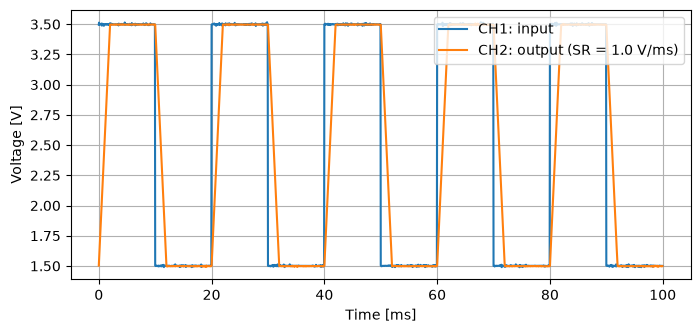

In [3]:
SLEW_V_PER_MS = 1.0

lab.fg.square(50, 1.0)
lab.mimic.slew_rate(SLEW_V_PER_MS * 1e-3)   # V/us
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"rising slope: {rising_slope(t, ch2):.3f} V/ms (setting {real_slew(SLEW_V_PER_MS):.3f} V/ms)")
show(t, ch1, ch2, f"SR = {SLEW_V_PER_MS} V/ms")

縁の傾きは、段差の大きさによらず SR で決まります。段差が大きいほど、上りきるまでに長くかかります。

## 実験 2:正弦波がゆがむ

振幅 1 V の正弦波を、SR = 1 V/ms に入れます。フルパワー帯域幅は $f_p$ = 1000 V/s /(2π × 1 V)= **159 Hz** です。100 Hz(最大の傾き 0.63 V/ms)ならそのまま通り、300 Hz(1.9 V/ms)では三角波になって、振幅は SR /(4f)= 0.84 V に小さくなるはずです。

100 Hz: largest slope of the input 0.63 V/ms, output amplitude 1.001 V (triangle SR / 4f = 2.518 V)
300 Hz: largest slope of the input 1.88 V/ms, output amplitude 0.831 V (triangle SR / 4f = 0.839 V)


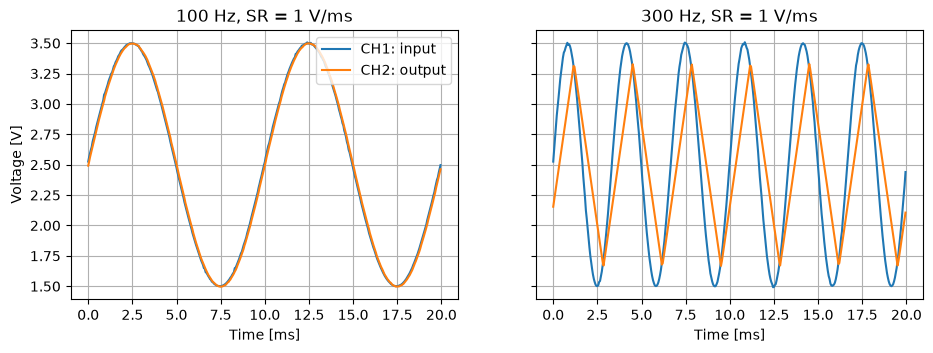

In [4]:
SR = real_slew(1.0) * 1e3   # V/s

lab.mimic.slew_rate(0.001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, f in zip(axes, (100, 300)):
    lab.fg.sine(f, 1.0)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(400)   # 20 ms
    amp = (ch2.max() - ch2.min()) / 2
    print(f"{f} Hz: largest slope of the input {2 * np.pi * f * 1.0 * 1e-3:.2f} V/ms, "
          f"output amplitude {amp:.3f} V (triangle SR / 4f = {SR / (4 * f):.3f} V)")
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label="CH2: output")
    ax.set_title(f"{f} Hz, SR = 1 V/ms")
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].legend(loc="upper right")
plt.show()

100 Hz では、出力は入力とほぼ重なります(三角波の式は当てはまりません)。300 Hz では、出力は傾き SR の三角波になり、入力の山に届く前に折り返します。

## 実験 3:振幅によって変わる周波数特性

振幅 1 V と 0.5 V で、周波数特性(ゲイン)を測ります。$f_p$ は 1 V で 159 Hz、0.5 V で 318 Hz です。$f_p$ より下ではゲイン 1(0 dB)、上では周波数が 2 倍で半分(−20 dB/decade)ずつ下がり、**振幅が小さいほど高い周波数まで通る**はずです。

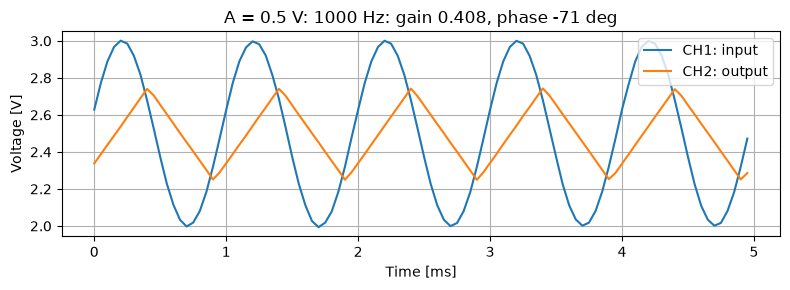

In [5]:
freqs = np.logspace(np.log10(20), np.log10(1000), 14)

lab.mimic.slew_rate(0.001)
mon = Monitor()
r1 = lab.frequency_response(freqs, amp=1.0, monitor=mon, label="A = 1 V: ")
r05 = lab.frequency_response(freqs, amp=0.5, monitor=mon, label="A = 0.5 V: ")
mon.close()

振幅 1 V で取り込んだ波形です(クリックで開きます)。


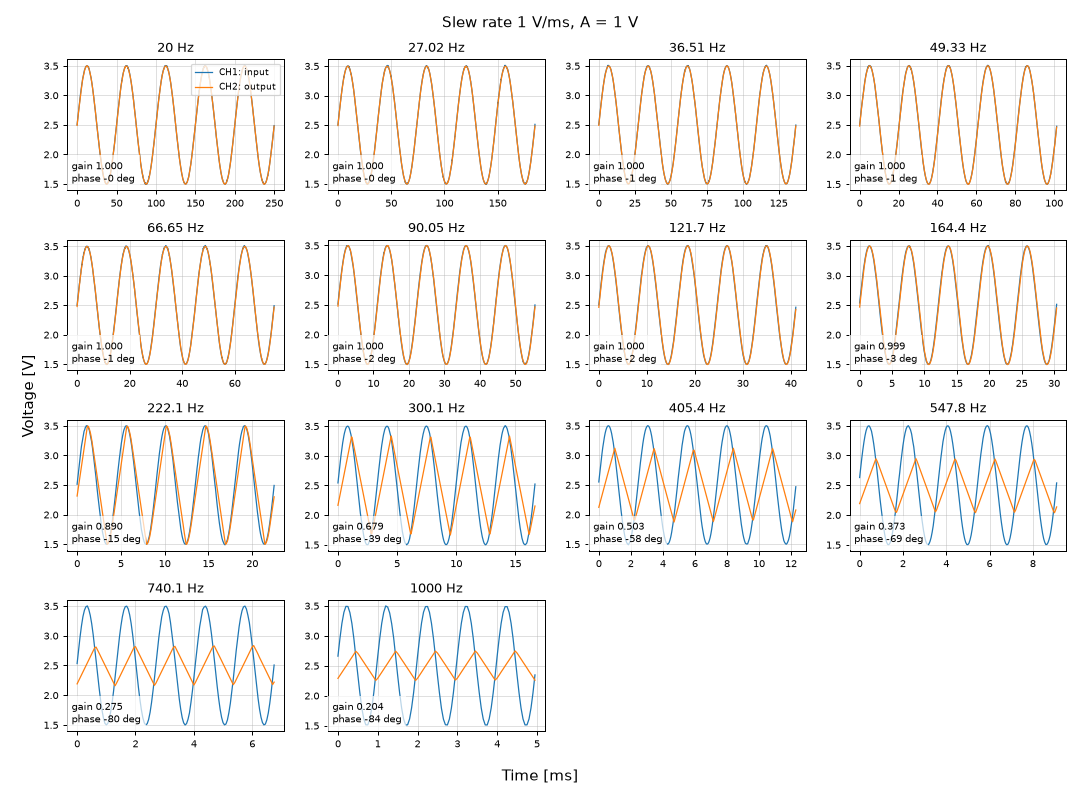

In [6]:
plot_waveforms(r1, title="Slew rate 1 V/ms, A = 1 V", collapsed=True)

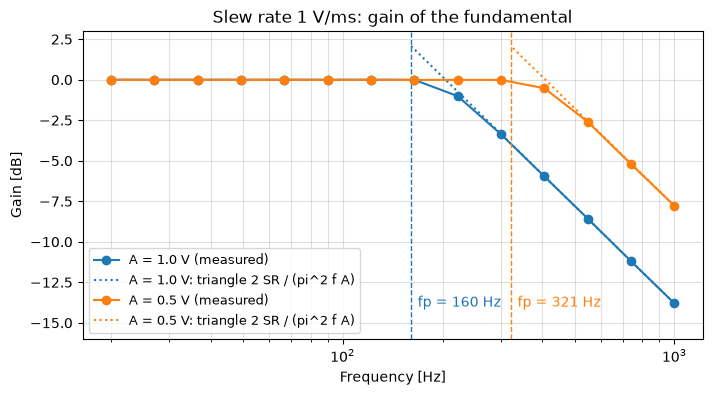

In [7]:
SR = real_slew(1.0) * 1e3   # V/s
f_th = np.logspace(np.log10(20), np.log10(1000), 200)

fig, ax = plt.subplots(figsize=(8, 4))
for r, a, c in ((r1, 1.0, "C0"), (r05, 0.5, "C1")):
    fp = SR / (2 * np.pi * a)
    ax.semilogx(r.freq, r.gain_db, "o-", color=c, label=f"A = {a} V (measured)")
    ax.semilogx(f_th[f_th > fp], 20 * np.log10(2 * SR / (np.pi**2 * f_th[f_th > fp] * a)), ":", color=c,
                label=f"A = {a} V: triangle 2 SR / (pi^2 f A)")
    ax.axvline(fp, color=c, ls="--", lw=1)
    ax.text(fp * 1.05, -14, f"fp = {fp:.0f} Hz", color=c)
ax.set_ylim(-16, 3)
ax.set_title("Slew rate 1 V/ms: gain of the fundamental")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Gain [dB]")
ax.grid(True, which="both", alpha=0.4)
ax.legend(loc="lower left", fontsize=9)
plt.show()

点線は、出力が三角波になりきったときの基本波のゲイン(三角波の振幅 SR /(4f)に、基本波の割合 8/π² を掛けたもの)です。$f_p$ のすぐ上では、出力はまだ三角波になりきらないので点線から少し離れます。

同じ回路なのに、振幅を半分にすると折れる周波数が 2 倍になります。オペアンプのデータシートの周波数特性(ゲインと帯域)は小さな信号で測った値で、大きな信号では、それより低い周波数から SR で制限されます。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. スルーレートを変える

50 Hz、振幅 1 V の方形波のまま、SR を変えて縁の傾きを見ます。
<details><summary>ヒント</summary>

`SLEW_V_PER_MS` を 2 → 0.5 → 0.1 と変えてみましょう(実験 1 は 1)。2 V の段差を上るのにかかる時間は 2 V / SR で、1 ms、4 ms、20 ms です。

- 0.1 V/ms では、半周期(10 ms)のうちに上りきれないので、出力は三角波になり、1 V しか動きません。
- SR は 0.03 V/ms きざみなので、0.1 V/ms は 0.092 V/ms になります(表示の setting)。

</details>

rising slope: 2.008 V/ms (setting 2.014 V/ms), output 1.49 - 3.51 V


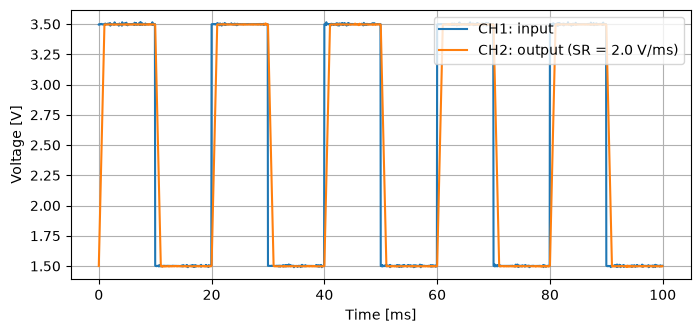

In [8]:
SLEW_V_PER_MS = 2.0

lab.fg.square(50, 1.0)
lab.mimic.slew_rate(SLEW_V_PER_MS * 1e-3)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"rising slope: {rising_slope(t, ch2, 2.0, 3.0):.3f} V/ms (setting {real_slew(SLEW_V_PER_MS):.3f} V/ms), "
      f"output {ch2.min():.2f} - {ch2.max():.2f} V")
show(t, ch1, ch2, f"SR = {SLEW_V_PER_MS} V/ms")

### 2. 振幅を変える

200 Hz の正弦波、SR = 1 V/ms のまま、振幅を変えます。
<details><summary>ヒント</summary>

`AMP` を 0.5 → 0.8 → 1.0 → 1.5 と変えてみましょう。$f_p$ = SR /(2πA)は 318、199、159、106 Hz です。

- 0.5 V:200 Hz は $f_p$ より下なので、そのまま通ります。
- 0.8 V:ちょうど $f_p$ のあたりで、まだほぼそのままです。
- 1.0 V:$f_p$ より上なので、0 V を横切るあたりが傾き SR の直線になり、入力より遅れます。ただ、山には追いつくので、振幅は 1 V のままです。
- 1.5 V:山に追いつけず、傾き SR の三角波に近い形になります。振幅は SR /(4f)= 1.26 V で頭打ちで、入力の 1.5 V より小さくなります。

</details>

fp = 321 Hz, output amplitude 0.499 V (input 0.5 V)


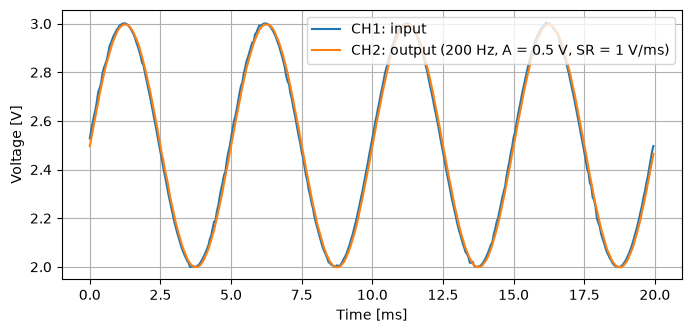

In [9]:
AMP = 0.5

lab.fg.sine(200, AMP)
lab.mimic.slew_rate(0.001)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(400)   # 20 ms
print(f"fp = {real_slew(1.0) * 1e3 / (2 * np.pi * AMP):.0f} Hz, output amplitude {(ch2.max() - ch2.min()) / 2:.3f} V "
      f"(input {AMP} V)")
show(t, ch1, ch2, f"200 Hz, A = {AMP} V, SR = 1 V/ms")

### 3. 三角波を入れる

振幅 1 V の三角波、SR = 1 V/ms で、周波数を変えます。
<details><summary>ヒント</summary>

`FREQ` を 200 → 250 → 300 → 500 と変えてみましょう。三角波の傾きは 4Af で、0.8、1.0、1.2、2.0 V/ms です。

- 200 Hz:傾きが SR より小さいので、そのまま通ります。
- 300 Hz、500 Hz:形は三角波のまま、傾きが SR になり、振幅は SR /(4f)= 0.84 V、0.50 V に小さくなります。正弦波と違って、形は変わらず小さくなるだけです。

</details>

slope of the input 0.80 V/ms, output amplitude 0.999 V


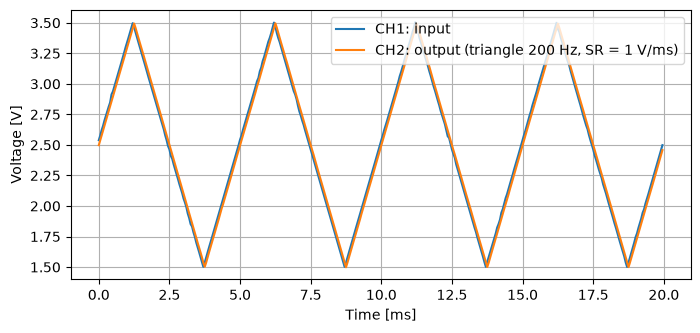

In [10]:
FREQ = 200

lab.fg.triangle(FREQ, 1.0)
lab.mimic.slew_rate(0.001)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(400)
print(f"slope of the input {4 * 1.0 * FREQ * 1e-3:.2f} V/ms, output amplitude {(ch2.max() - ch2.min()) / 2:.3f} V")
show(t, ch1, ch2, f"triangle {FREQ} Hz, SR = 1 V/ms")

## まとめ

- オペアンプの出力の変化の速さには上限(スルーレート SR = I / Cc)がある。段差は傾き SR の斜めの線になる。
- 正弦波は、最大の傾き 2πfA が SR を超えるとゆがむ。ゆがまない最高の周波数(フルパワー帯域幅)は $f_p$ = SR /(2πA)で、**振幅が大きいほど低い**。
- Mimic では `slew_rate(sr)`(V/µs)。この講義では 1 V/ms 程度に遅くして見た。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [11]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()